In [56]:
import warnings
import os
import json
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, norm
from scipy.spatial.distance import pdist, squareform

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score
)

import skfuzzy as fuzz

from IPython.display import display

In [57]:
FILE_PATH = "/Users/lunaaqillah/Documents/SKRIPSI/dataa.xlsx"
SHEET_NAME = "DATA ASLI"

RANDOM_STATE = 42

K = 3
C = 3

M = 2.0
ERROR = 0.005
MAXITER = 1000

print("Library berhasil di-import.")
print(f"K-Means : k = {K}")
print(f"FCM     : c = {C}")

Library berhasil di-import.
K-Means : k = 3
FCM     : c = 3


INPUT DATA

In [58]:
raw = pd.read_excel(
    FILE_PATH,
    sheet_name=SHEET_NAME,
    header=None
)

print("Ukuran data mentah :", raw.shape)

display(raw.head())

Ukuran data mentah : (402, 77)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76
0,X1,X1,X1,X1,X2,X2,X2,X2,X2,X3,X3,X3,X3,X3,X3,X4,X4,X4,X4,X4,X4,X4,X4,X4,X4,X4,X4,X5,X5,X5,X5,X5,X5,X5,X5,X5,X6,X6,X6,X6,X6,X6,X7,X7,X7,X7,X7,X7,X7,X7,X7,X8,X8,X8,X8,X8,X8,X9,X9,X9,X9,X9,X9,X9,X9,X9,X9,X9,X9,X10,X10,X10,X10,X10,X10,Y,Y
1,X1.1.1,X1.1.2,X1.2.1,X1.2.2,X2.1.1,X2.1.2,X2.2.1,X2.2.2,X2.2.3,X3.1.1,X3.1.2,X3.1.3,X3.2.1,X3.2.2,X3.2.3,X4.1.1,X4.1.2,X4.1.3,X4.2.1,X4.2.2,X4.2.3,X4.3.1,X4.3.2,X4.3.3,X4.4.1,X4.4.2,X4.4.3,X5.1.1,X5.1.2,X5.1.3,X5.2.1,X5.2.2,X5.2.3,X5.3.1,X5.3.2,X5.3.3,X6.1.1,X6.1.2,X6.1.3,X6.2.1,X6.2.2,X6.2.3,X7.1.1,X7.1.2,X7.1.3,X7.2.1,X7.2.2,X7.2.3,X7.3.1,X7.3.2,X7.3.3,X8.1.1,X8.1.2,X8.1.3,X8.2.1,X8.2.2,X8.2.3,X9.1.1,X9.1.2,X9.1.3,X9.1.4,X9.2.1,X9.2.2,X9.2.3,X9.2.4,X9.3.1,X9.3.2,X9.3.3,X9.3.4,X10.1.1,X10.1.2,X10.1.3,X10.2.1,X10.2.2,X10.2.3,Y.1,Y.2
2,4,4,3,4,4,4,4,4,5,3,4,5,4,5,4,4,4,4,3,5,4,5,5,4,3,3,4,4,4,3,4,4,4,4,4,4,3,5,4,4,4,5,3,3,3,4,5,4,5,4,3,3,3,4,4,5,5,3,4,5,4,4,3,4,3,5,5,5,3,5,4,5,4,5,4,4,5
3,5,5,4,4,4,4,4,4,5,4,4,4,4,3,4,3,4,3,3,4,4,4,3,5,3,4,4,5,5,4,5,5,4,4,4,4,4,4,4,4,4,4,4,4,5,5,4,5,4,3,4,3,4,4,4,4,4,4,5,4,4,4,5,4,4,4,3,5,4,4,4,4,4,5,3,4,4
4,4,5,5,5,5,5,4,4,4,3,3,3,4,4,3,4,5,4,4,4,4,4,3,4,5,3,4,4,3,5,4,4,4,4,3,3,5,4,4,3,3,4,5,4,4,4,4,4,4,5,3,3,4,5,3,4,3,5,4,5,4,4,4,3,4,4,4,3,4,4,4,5,5,3,4,4,5


In [59]:
variabel_header = raw.iloc[0]
item_header = raw.iloc[1]

column_names = [
    f"{var}_{item}"
    for var, item in zip(
        variabel_header,
        item_header
    )
]

df = raw.iloc[2:].copy()

df.columns = column_names

df = df.reset_index(drop=True)

df = df.apply(
    pd.to_numeric,
    errors="coerce"
)

print("Ukuran data:")
print(df.shape)

display(df.head())

Ukuran data:
(400, 77)


,X1_X1.1.1,X1_X1.1.2,X1_X1.2.1,X1_X1.2.2,X2_X2.1.1,X2_X2.1.2,X2_X2.2.1,X2_X2.2.2,X2_X2.2.3,X3_X3.1.1,X3_X3.1.2,X3_X3.1.3,X3_X3.2.1,X3_X3.2.2,X3_X3.2.3,X4_X4.1.1,X4_X4.1.2,X4_X4.1.3,X4_X4.2.1,X4_X4.2.2,X4_X4.2.3,X4_X4.3.1,X4_X4.3.2,X4_X4.3.3,X4_X4.4.1,X4_X4.4.2,X4_X4.4.3,X5_X5.1.1,X5_X5.1.2,X5_X5.1.3,X5_X5.2.1,X5_X5.2.2,X5_X5.2.3,X5_X5.3.1,X5_X5.3.2,X5_X5.3.3,X6_X6.1.1,X6_X6.1.2,X6_X6.1.3,X6_X6.2.1,X6_X6.2.2,X6_X6.2.3,X7_X7.1.1,X7_X7.1.2,X7_X7.1.3,X7_X7.2.1,X7_X7.2.2,X7_X7.2.3,X7_X7.3.1,X7_X7.3.2,X7_X7.3.3,X8_X8.1.1,X8_X8.1.2,X8_X8.1.3,X8_X8.2.1,X8_X8.2.2,X8_X8.2.3,X9_X9.1.1,X9_X9.1.2,X9_X9.1.3,X9_X9.1.4,X9_X9.2.1,X9_X9.2.2,X9_X9.2.3,X9_X9.2.4,X9_X9.3.1,X9_X9.3.2,X9_X9.3.3,X9_X9.3.4,X10_X10.1.1,X10_X10.1.2,X10_X10.1.3,X10_X10.2.1,X10_X10.2.2,X10_X10.2.3,Y_Y.1,Y_Y.2
0,4,4,3,4,4,4,4,4,5,3,4,5,4,5,4,4,4,4,3,5,4,5,5,4,3,3,4,4,4,3,4,4,4,4,4,4,3,5,4,4,4,5,3,3,3,4,5,4,5,4,3,3,3,4,4,5,5,3,4,5,4,4,3,4,3,5,5,5,3,5,4,5,4,5,4,4,5
1,5,5,4,4,4,4,4,4,5,4,4,4,4,3,4,3,4,3,3,4,4,4,3,5,3,4,4,5,5,4,5,5,4,4,4,4,4,4,4,4,4,4,4,4,5,5,4,5,4,3,4,3,4,4,4,4,4,4,5,4,4,4,5,4,4,4,3,5,4,4,4,4,4,5,3,4,4
2,4,5,5,5,5,5,4,4,4,3,3,3,4,4,3,4,5,4,4,4,4,4,3,4,5,3,4,4,3,5,4,4,4,4,3,3,5,4,4,3,3,4,5,4,4,4,4,4,4,5,3,3,4,5,3,4,3,5,4,5,4,4,4,3,4,4,4,3,4,4,4,5,5,3,4,4,5
3,4,4,4,4,2,3,4,5,4,4,2,2,3,3,4,4,4,3,5,5,3,5,4,3,4,4,4,4,4,4,3,5,3,2,3,3,4,2,5,5,5,3,3,3,3,4,4,5,2,4,4,4,3,4,5,3,2,4,4,5,3,4,4,4,3,3,2,3,3,4,3,4,3,5,3,2,3
4,3,4,4,3,2,3,2,3,4,5,4,5,3,3,5,4,3,4,5,3,4,4,3,4,3,5,5,4,4,2,4,3,2,3,4,2,3,4,4,4,3,2,3,5,2,3,3,3,2,4,3,3,4,3,5,5,2,4,4,2,3,5,3,2,4,5,4,4,5,5,3,5,2,5,3,4,5


In [60]:
variable_groups = {}

for i in range(1, 11):

    variable_groups[f"X{i}"] = [
        col
        for col in df.columns
        if col.startswith(f"X{i}_")
    ]

variable_groups["Y"] = [
    col
    for col in df.columns
    if col.startswith("Y_")
]

ringkasan_item = pd.DataFrame({
    "Variabel": variable_groups.keys(),
    "Jumlah Item": [
        len(items)
        for items in variable_groups.values()
    ]
})

display(ringkasan_item)

,Variabel,Jumlah Item
0,X1,4
1,X2,5
2,X3,6
3,X4,12
4,X5,9
5,X6,6
6,X7,9
7,X8,6
8,X9,12
9,X10,6


PREPROCESSING DATA

In [61]:
print("========== DATA CHECKING ==========")

print("\nJumlah responden :", df.shape[0])
print("Jumlah item      :", df.shape[1])

missing = df.isna().sum().sum()

print("\nTotal missing value :", missing)

duplicate = df.duplicated().sum()

print("Jumlah baris duplikat :", duplicate)

print("\nNilai minimum :", df.min().min())
print("Nilai maksimum:", df.max().max())

invalid = ((df < 1) | (df > 5)).sum().sum()

print("\nNilai di luar skala 1-5 :", invalid)

========== DATA CHECKING ==========

Jumlah responden : 400
Jumlah item      : 77

Total missing value : 0
Jumlah baris duplikat : 0

Nilai minimum : 1
Nilai maksimum: 5

Nilai di luar skala 1-5 : 0


In [62]:
for var, items in variable_groups.items():

    print(f"\n{var} ({len(items)} item)")

    for item in items:
        print("  -", item)


X1 (4 item)
  - X1_X1.1.1
  - X1_X1.1.2
  - X1_X1.2.1
  - X1_X1.2.2

X2 (5 item)
  - X2_X2.1.1
  - X2_X2.1.2
  - X2_X2.2.1
  - X2_X2.2.2
  - X2_X2.2.3

X3 (6 item)
  - X3_X3.1.1
  - X3_X3.1.2
  - X3_X3.1.3
  - X3_X3.2.1
  - X3_X3.2.2
  - X3_X3.2.3

X4 (12 item)
  - X4_X4.1.1
  - X4_X4.1.2
  - X4_X4.1.3
  - X4_X4.2.1
  - X4_X4.2.2
  - X4_X4.2.3
  - X4_X4.3.1
  - X4_X4.3.2
  - X4_X4.3.3
  - X4_X4.4.1
  - X4_X4.4.2
  - X4_X4.4.3

X5 (9 item)
  - X5_X5.1.1
  - X5_X5.1.2
  - X5_X5.1.3
  - X5_X5.2.1
  - X5_X5.2.2
  - X5_X5.2.3
  - X5_X5.3.1
  - X5_X5.3.2
  - X5_X5.3.3

X6 (6 item)
  - X6_X6.1.1
  - X6_X6.1.2
  - X6_X6.1.3
  - X6_X6.2.1
  - X6_X6.2.2
  - X6_X6.2.3

X7 (9 item)
  - X7_X7.1.1
  - X7_X7.1.2
  - X7_X7.1.3
  - X7_X7.2.1
  - X7_X7.2.2
  - X7_X7.2.3
  - X7_X7.3.1
  - X7_X7.3.2
  - X7_X7.3.3

X8 (6 item)
  - X8_X8.1.1
  - X8_X8.1.2
  - X8_X8.1.3
  - X8_X8.2.1
  - X8_X8.2.2
  - X8_X8.2.3

X9 (12 item)
  - X9_X9.1.1
  - X9_X9.1.2
  - X9_X9.1.3
  - X9_X9.1.4
  - X9_X9.2.1
  - X9_X9.2.2

ANALISIS DESKRIPTIF

In [63]:
deskriptif_item = df.describe().T[
    [
        "count",
        "mean",
        "std",
        "min",
        "max"
    ]
]

deskriptif_item.round(3)

,count,mean,std,min,max
X1_X1.1.1,400.0,3.755,0.996,1.0,5.0
X1_X1.1.2,400.0,3.800,0.963,1.0,5.0
X1_X1.2.1,400.0,3.872,0.958,1.0,5.0
X1_X1.2.2,400.0,3.810,1.006,1.0,5.0
X2_X2.1.1,400.0,3.800,1.004,1.0,5.0
X2_X2.1.2,400.0,3.772,0.994,1.0,5.0
X2_X2.2.1,400.0,3.768,1.000,1.0,5.0
X2_X2.2.2,400.0,3.815,0.997,1.0,5.0
X2_X2.2.3,400.0,3.715,1.030,1.0,5.0
X3_X3.1.1,400.0,3.688,1.014,1.0,5.0


In [64]:
# Membuat skor rata-rata untuk setiap variabel X1–X10
df_konstruk = pd.DataFrame(index=df.index)

for i in range(1, 11):
    
    # Mengambil seluruh item dari masing-masing variabel
    kolom_x = [
        col for col in df.columns
        if col.startswith(f"X{i}_")
    ]
    
    # Menghitung rata-rata item sebagai skor variabel
    df_konstruk[f"X{i}"] = df[kolom_x].mean(axis=1)


# Analisis deskriptif X1–X10
deskriptif_konstruk = df_konstruk.describe().T[
    [
        "count",
        "mean",
        "std",
        "min",
        "max"
    ]
]

# Mengganti nama kolom agar lebih akademis
deskriptif_konstruk.columns = [
    "N",
    "Mean",
    "Std. Deviasi",
    "Minimum",
    "Maksimum"
]

# Menampilkan seluruh hasil
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

display(deskriptif_konstruk.round(3))

,N,Mean,Std. Deviasi,Minimum,Maksimum
X1,400.0,3.809,0.650,1.250,5.000
X2,400.0,3.774,0.635,1.400,5.000
X3,400.0,3.752,0.650,2.000,5.000
X4,400.0,3.798,0.535,2.333,4.750
X5,400.0,3.775,0.576,2.000,4.889
X6,400.0,3.762,0.622,2.000,5.000
X7,400.0,3.780,0.576,1.889,4.889
X8,400.0,3.749,0.646,1.667,4.833
X9,400.0,3.790,0.552,2.417,4.917
X10,400.0,3.784,0.618,1.500,5.000


MSI

In [65]:
def msi_transform(series):

    series = pd.to_numeric(
        series,
        errors="coerce"
    )

    categories = np.arange(1, 6)

    frequency = (
        series
        .value_counts()
        .reindex(
            categories,
            fill_value=0
        )
        .astype(float)
    )

    proportion = (
        frequency /
        frequency.sum()
    )

    cumulative = proportion.cumsum()

    cumulative_lower = (
        cumulative.shift(
            fill_value=0
        )
    )

    cumulative_upper = cumulative.copy()

    z_lower = np.where(
        cumulative_lower == 0,
        -np.inf,
        norm.ppf(cumulative_lower)
    )

    z_upper = np.where(
        cumulative_upper == 1,
        np.inf,
        norm.ppf(cumulative_upper)
    )

    density_lower = norm.pdf(z_lower)
    density_upper = norm.pdf(z_upper)

    scale_value = (
        (density_lower - density_upper)
        / proportion.replace(0, np.nan)
    )

    min_scale = scale_value.min()

    msi_value = (
        scale_value -
        min_scale +
        1
    )

    mapping = msi_value.to_dict()

    transformed = series.map(mapping)

    # Tabel perhitungan MSI
    tabel = pd.DataFrame({
        "Frekuensi": frequency.astype(int),
        "Proporsi": proportion,
        "Proporsi Kumulatif Bawah": cumulative_lower,
        "Proporsi Kumulatif Atas": cumulative_upper,
        "Z Bawah": z_lower,
        "Z Atas": z_upper,
        "Density Bawah": density_lower,
        "Density Atas": density_upper,
        "Scale Value": scale_value,
        "Nilai MSI": msi_value
    })

    return transformed, tabel

In [66]:
contoh_item = variable_groups["X1"][0]

hasil_msi_contoh, tabel_msi_contoh = (
    msi_transform(
        df[contoh_item]
    )
)

print("Item :", contoh_item)

display(
    tabel_msi_contoh.round(4)
)

Item : X1_X1.1.1


,Frekuensi,Proporsi,Proporsi Kumulatif Bawah,Proporsi Kumulatif Atas,Z Bawah,Z Atas,Density Bawah,Density Atas,Scale Value,Nilai MSI
X1_X1.1.1,,,,,,,,,,
1,12,0.0300,0.0000,0.0300,-inf,-1.8808,0.0000,0.0680,-2.2681,1.0000
2,33,0.0825,0.0300,0.1125,-1.8808,-1.2133,0.0680,0.1911,-1.4914,1.7766
3,88,0.2200,0.1125,0.3325,-1.2133,-0.4330,0.1911,0.3632,-0.7825,2.4855
4,175,0.4375,0.3325,0.7700,-0.4330,0.7388,0.3632,0.3036,0.1362,3.4043
5,92,0.2300,0.7700,1.0000,0.7388,inf,0.3036,0.0000,1.3202,4.5883


In [99]:
df_msi = pd.DataFrame(
    index=df.index
)

tabel_msi_semua = {}

for var in [f"X{i}" for i in range(1, 11)]:

    for item in variable_groups[var]:

        hasil, tabel = msi_transform(
            df[item]
        )

        df_msi[item] = hasil

        tabel_msi_semua[item] = tabel

print(
    "Jumlah item setelah MSI:",
    df_msi.shape[1]
)

display(df_msi)

Jumlah item setelah MSI: 75


,X1_X1.1.1,X1_X1.1.2,X1_X1.2.1,X1_X1.2.2,X2_X2.1.1,X2_X2.1.2,X2_X2.2.1,X2_X2.2.2,X2_X2.2.3,X3_X3.1.1,X3_X3.1.2,X3_X3.1.3,X3_X3.2.1,X3_X3.2.2,X3_X3.2.3,X4_X4.1.1,X4_X4.1.2,X4_X4.1.3,X4_X4.2.1,X4_X4.2.2,X4_X4.2.3,X4_X4.3.1,X4_X4.3.2,X4_X4.3.3,X4_X4.4.1,X4_X4.4.2,X4_X4.4.3,X5_X5.1.1,X5_X5.1.2,X5_X5.1.3,X5_X5.2.1,X5_X5.2.2,X5_X5.2.3,X5_X5.3.1,X5_X5.3.2,X5_X5.3.3,X6_X6.1.1,X6_X6.1.2,X6_X6.1.3,X6_X6.2.1,X6_X6.2.2,X6_X6.2.3,X7_X7.1.1,X7_X7.1.2,X7_X7.1.3,X7_X7.2.1,X7_X7.2.2,X7_X7.2.3,X7_X7.3.1,X7_X7.3.2,X7_X7.3.3,X8_X8.1.1,X8_X8.1.2,X8_X8.1.3,X8_X8.2.1,X8_X8.2.2,X8_X8.2.3,X9_X9.1.1,X9_X9.1.2,X9_X9.1.3,X9_X9.1.4,X9_X9.2.1,X9_X9.2.2,X9_X9.2.3,X9_X9.2.4,X9_X9.3.1,X9_X9.3.2,X9_X9.3.3,X9_X9.3.4,X10_X10.1.1,X10_X10.1.2,X10_X10.1.3,X10_X10.2.1,X10_X10.2.2,X10_X10.2.3
0,3.404275,3.444175,2.650797,3.337443,3.384079,3.600459,3.420807,3.493176,4.581979,2.625984,3.557117,4.630726,3.677696,4.397972,3.409398,3.918409,3.503759,3.319745,2.656921,4.608909,3.566472,4.648445,4.683683,3.497662,2.754593,2.685105,3.669335,3.407274,3.501097,2.686151,3.426616,3.587132,3.629555,3.410513,3.416794,3.572558,2.742204,4.740637,3.356139,3.298167,3.477368,4.688497,2.702802,2.655834,2.739018,3.486513,4.575730,3.383445,4.521452,3.616968,2.579872,2.571048,2.679950,3.598581,3.424623,4.478661,4.710098,2.643631,3.391063,4.728785,3.409908,3.477322,2.677316,3.578862,2.772370,4.721408,4.711299,4.579565,2.469730,4.867440,3.458782,4.639872,3.397203,4.921617,3.539526
1,4.588274,4.639265,3.554290,3.337443,3.384079,3.600459,3.420807,3.493176,4.581979,3.515649,3.557117,3.453339,3.677696,2.396586,3.409398,3.007594,3.503759,2.436977,2.656921,3.427182,3.566472,3.482987,2.666925,4.716212,2.754593,3.561345,3.669335,4.591190,4.690228,3.613677,4.585112,4.743661,3.629555,3.410513,3.416794,3.572558,3.680597,3.626880,3.356139,3.298167,3.477368,3.544954,3.564466,3.528428,4.770994,4.634259,3.381120,4.539171,3.383012,2.698795,3.425488,2.571048,3.511979,3.598581,3.424623,3.338645,3.578822,3.582116,4.578654,3.558671,3.409908,3.477322,4.838609,3.578862,3.653346,3.580347,2.684821,4.579565,3.383682,3.727423,3.458782,3.502807,3.397203,4.921617,2.635483
2,3.404275,4.639265,4.721408,4.515624,4.554949,4.717090,3.420807,3.493176,3.426785,2.625984,2.657681,2.556689,3.677696,3.246015,2.578719,3.918409,4.692013,3.319745,3.548194,3.427182,3.566472,3.482987,2.666925,3.497662,4.871793,2.685105,3.669335,3.407274,2.552379,4.779931,3.426616,3.587132,3.629555,3.410513,2.535749,2.673663,4.851248,3.626880,3.356139,2.438711,2.577916,3.544954,4.694144,3.528428,3.614904,3.486513,3.381120,3.383445,3.383012,4.778083,2.579872,2.571048,3.511979,4.722369,2.549567,3.338645,2.726898,4.758723,3.391063,4.728785,3.409908,3.477322,3.621547,2.708662,3.653346,3.580347,3.551836,2.679565,3.383682,3.727423,3.458782,4.639872,4.560816,2.879544,3.539526
3,3.404275,3.444175,3.554290,3.337443,1.789530,2.725203,3.420807,4.645520,3.426785,3.515649,1.913158,1.830722,2.789235,2.396586,3.409398,3.918409,3.503759,2.436977,4.688497,4.608909,2.662924,4.648445,3.542992,2.523195,3.691347,3.561345,3.669335,3.407274,3.501097,3.613677,2.541343,4.743661,2.732121,1.769670,2.535749,2.673663,3.680597,1.956631,4.532198,4.422038,4.640948,2.637206,2.702802,2.655834,2.739018,3.486513,3.381120,4.539171,1.825272,3.616968,3.425488,3.450366,2.679950,3.598581,4.613945,2.485408,1.953947,3.582116,3.391063,4.728785,2.520099,3.477322,3.621547,3.578862,2.772370,2.725258,1.930826,2.679565,2.469730,3.727423,2.589610,3.502807,2.530450,4.921617,2.635483
4,2.485544,3.444175,3.554290,2.443325,1.789530,2.725203,1.806596,2.621470,3.426785,4.628114,3.557117,4.630726,2.789235,2.396586,4.526174,3.918409,2.559632,3.319745,4.688497,2.511066,3.566472,3.482987,2.666925,3.497662,2.754593,4.699827,4.801788,3.407274,3.501097,1.887388,3.426616,2.665112,1.895530,2.487715,3.416794,1.878558,2.742204,3.626880,3.356139,3.298167,2.577916,1.825754,2.702802,4.654432,1.965008,2.626416,2.460563,2.503141,1.825272,3.616968,2.579872,2.571048,3.511979,2.714571,4.613945,4.478661,1.953947,3.582116,3.391

AGREGASI ITEM

In [68]:
# ==========================================
# STANDARDISASI ITEM
# ==========================================

scaler_item = StandardScaler()

df_msi_z = pd.DataFrame(
    scaler_item.fit_transform(df_msi),
    columns=df_msi.columns,
    index=df_msi.index
)

print("Ukuran data setelah standardisasi item:")
print(df_msi_z.shape)

display(df_msi_z.head())

Ukuran data setelah standardisasi item:
(400, 75)


,X1_X1.1.1,X1_X1.1.2,X1_X1.2.1,X1_X1.2.2,X2_X2.1.1,X2_X2.1.2,X2_X2.2.1,X2_X2.2.2,X2_X2.2.3,X3_X3.1.1,X3_X3.1.2,X3_X3.1.3,X3_X3.2.1,X3_X3.2.2,X3_X3.2.3,X4_X4.1.1,X4_X4.1.2,X4_X4.1.3,X4_X4.2.1,X4_X4.2.2,X4_X4.2.3,X4_X4.3.1,X4_X4.3.2,X4_X4.3.3,X4_X4.4.1,X4_X4.4.2,X4_X4.4.3,X5_X5.1.1,X5_X5.1.2,X5_X5.1.3,X5_X5.2.1,X5_X5.2.2,X5_X5.2.3,X5_X5.3.1,X5_X5.3.2,X5_X5.3.3,X6_X6.1.1,X6_X6.1.2,X6_X6.1.3,X6_X6.2.1,X6_X6.2.2,X6_X6.2.3,X7_X7.1.1,X7_X7.1.2,X7_X7.1.3,X7_X7.2.1,X7_X7.2.2,X7_X7.2.3,X7_X7.3.1,X7_X7.3.2,X7_X7.3.3,X8_X8.1.1,X8_X8.1.2,X8_X8.1.3,X8_X8.2.1,X8_X8.2.2,X8_X8.2.3,X9_X9.1.1,X9_X9.1.2,X9_X9.1.3,X9_X9.1.4,X9_X9.2.1,X9_X9.2.2,X9_X9.2.3,X9_X9.2.4,X9_X9.3.1,X9_X9.3.2,X9_X9.3.3,X9_X9.3.4,X10_X10.1.1,X10_X10.1.2,X10_X10.1.3,X10_X10.2.1,X10_X10.2.2,X10_X10.2.3
0,0.145073,0.113621,-0.936122,0.074090,0.088033,0.139321,0.127018,0.077116,1.394952,-0.715718,0.145072,1.338225,0.095030,1.394118,0.114693,0.028419,0.088584,0.088419,-0.867501,1.356920,0.154864,1.354648,1.426079,0.082261,-0.890988,-0.836351,0.153995,0.074230,0.173921,-0.780693,0.052671,0.066794,0.111832,0.244137,0.122647,0.161235,-0.833458,1.350053,0.127014,0.125402,0.186693,1.302350,-0.817103,-0.766412,-0.776891,0.070018,1.394950,0.122801,1.332818,0.098516,-0.808530,-0.776246,-0.843785,0.188581,0.166508,1.321572,1.368729,-0.881409,0.095516,1.343912,0.115409,0.106945,-0.906742,0.116568,-0.800978,1.278484,1.324614,1.279174,-0.817110,1.285955,0.128736,1.299144,0.101892,1.417987,0.126355
1,1.406114,1.390153,0.031701,0.074090,0.088033,0.139321,0.127018,0.077116,1.394952,0.226809,0.145072,0.081145,0.095030,-0.729438,0.114693,-0.949815,0.088584,-0.853660,-0.867501,0.095413,0.154864,0.112592,-0.710854,1.388207,-0.890988,0.097892,0.153995,1.339248,1.440433,0.204823,1.290953,1.304044,0.111832,0.244137,0.122647,0.161235,0.166056,0.167121,0.127014,0.125402,0.186693,0.080582,0.101173,0.160494,1.384087,1.294929,0.120602,1.352866,0.122231,-0.881786,0.093539,-0.776246,0.045361,0.188581,0.166508,0.108291,0.167658,0.120151,1.362908,0.095133,0.115409,0.106945,1.405960,0.116568,0.136970,0.059455,-0.837063,1.279174,0.156346,0.066541,0.128736,0.087287,0.101892,1.417987,-0.836649
2,0.145073,1.390153,1.281921,1.332290,1.337161,1.327536,0.127018,0.077116,0.168510,-0.715718,-0.812884,-0.876198,0.095030,0.171843,-0.768802,0.028419,1.359053,0.088419,0.083976,0.095413,0.154864,0.112592,-0.710854,0.082261,1.370667,-0.836351,0.153995,0.074230,-0.836535,1.443991,0.052671,0.066794,0.111832,0.244137,-0.815085,-0.794466,1.412957,0.167121,0.127014,-0.788775,-0.768456,0.080582,1.305071,0.160494,0.154602,0.070018,0.120602,0.122801,0.122231,1.338200,-0.808530,-0.776246,0.045361,1.381354,-0.764159,0.108291,-0.736826,1.375837,0.095516,1.343912,0.115409,0.106945,0.103636,-0.811234,0.136970,0.059455,0.087796,-0.742435,0.156346,0.066541,0.128736,1.299144,1.341540,-0.754371,0.126355
3,0.145073,0.113621,0.031701,0.074090,-1.613093,-0.792045,0.127018,1.306750,0.168510,0.226809,-1.605849,-1.651303,-0.853379,-0.729438,0.114693,0.028419,0.088584,-0.853660,1.301305,1.356920,-0.806404,1.354648,0.217416,-0.962098,0.109680,0.097892,0.153995,0.074230,0.173921,0.204823,-0.893571,1.304044,-0.845276,-1.495733,-0.815085,-0.794466,0.166056,-1.606864,1.379696,1.320831,1.422326,-0.889261,-0.817103,-0.766412,-0.776891,0.070018,0.120602,1.352866,-1.534227,0.098516,0.093539,0.158120,-0.843785,0.188581,1.431412,-0.799780,-1.557464,0.120151,0.095516,1.343912,-0.832398,0.106945,0.103636,0.116568,-0.800978,-0.854063,-1.641362,-0.742435,-0.817110,0.066541,-0.796162,0.087287,-0.821500,1.417987,-0.836649
4,-0.833438,0.113621,0.031701,-0.880755,-1.613093,-0.792045,-1.592404,-0.853057,0.168510,1.405372,0.145072,1.338225,-0.853379,-0.729438,1.302476,0.028419,-0.920866,0.088419,1.301305,-0.882551,0.154864,0.112592,-0.710854,0.082261,-0.890988,1.311733,1.359695,0.074230,0.173921,-1.629395,0.052671,-0.919579,-1.737495,-0.734352,0.122647,-1.639819,-0.833458,0.167121,0.127014,0.125402,-0.768456,-1.756221,-0.817103,1.356580,-1.600038,-0.847906,-0.861401,-0.

In [69]:
# ==========================================
# AGREGASI ITEM TERSTANDARISASI
# ==========================================

df_z_variable = pd.DataFrame(
    index=df_msi_z.index
)

for var in [
    f"X{i}"
    for i in range(1, 11)
]:

    items = variable_groups[var]

    df_z_variable[var] = (
        df_msi_z[items]
        .mean(axis=1)
    )

print(
    "Ukuran data setelah agregasi:",
    df_z_variable.shape
)

display(df_z_variable.head())

Ukuran data setelah agregasi: (400, 10)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10
0,-0.150835,0.365288,0.395237,0.178279,0.025197,0.376342,-0.016648,0.237560,0.187865,0.726678
1,0.725514,0.365288,-0.011115,-0.181773,0.691039,0.142145,0.416459,-0.016641,0.343163,0.160966
2,1.037359,0.607468,-0.484455,0.165204,-0.050270,0.038407,0.287276,-0.123704,0.169013,0.367991
3,0.091121,-0.160572,-0.749744,0.173892,-0.343013,0.298797,-0.239899,-0.237153,-0.316801,-0.147082
4,-0.392218,-0.936418,0.434722,0.086169,-0.693019,-0.489766,-0.647582,-0.047510,-0.030267,0.134000


STANDARISASI Z-SCORE

In [70]:
# ==========================================
# DATA AKHIR UNTUK CLUSTERING
# ==========================================

X_z = df_z_variable.copy()

print("Data akhir untuk clustering:")
print("Ukuran data:", X_z.shape)

display(X_z.head())

Data akhir untuk clustering:
Ukuran data: (400, 10)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10
0,-0.150835,0.365288,0.395237,0.178279,0.025197,0.376342,-0.016648,0.237560,0.187865,0.726678
1,0.725514,0.365288,-0.011115,-0.181773,0.691039,0.142145,0.416459,-0.016641,0.343163,0.160966
2,1.037359,0.607468,-0.484455,0.165204,-0.050270,0.038407,0.287276,-0.123704,0.169013,0.367991
3,0.091121,-0.160572,-0.749744,0.173892,-0.343013,0.298797,-0.239899,-0.237153,-0.316801,-0.147082
4,-0.392218,-0.936418,0.434722,0.086169,-0.693019,-0.489766,-0.647582,-0.047510,-0.030267,0.134000


In [71]:
# ==========================================
# EUCLIDEAN DISTANCE
# ==========================================

# Variabel yang digunakan untuk clustering
variabel_x = [f"X{i}" for i in range(1, 11)]

# Mengambil data yang SUDAH distandardisasi (Z-score)
data_euclidean = X_z[variabel_x]

# Menghitung Euclidean Distance
distance_matrix = squareform(
    pdist(
        data_euclidean,
        metric="euclidean"
    )
)

# Membuat DataFrame matriks jarak
df_euclidean = pd.DataFrame(
    distance_matrix,
    index=[f"R{i}" for i in range(1, len(data_euclidean) + 1)],
    columns=[f"R{i}" for i in range(1, len(data_euclidean) + 1)]
)

# Menampilkan Euclidean Distance
print("\nMatriks Euclidean Distance:")
display(df_euclidean.round(3))


Matriks Euclidean Distance:


,R1,R2,R3,R4,R5,R6,R7,R8,R9,R10,R11,R12,R13,R14,R15,R16,R17,R18,R19,R20,R21,R22,R23,R24,R25,R26,R27,R28,R29,R30,R31,R32,R33,R34,R35,R36,R37,R38,R39,R40,R41,R42,R43,R44,R45,R46,R47,R48,R49,R50,R51,R52,R53,R54,R55,R56,R57,R58,R59,R60,R61,R62,R63,R64,R65,R66,R67,R68,R69,R70,R71,R72,R73,R74,R75,R76,R77,R78,R79,R80,R81,R82,R83,R84,R85,R86,R87,R88,R89,R90,R91,R92,R93,R94,R95,R96,R97,R98,R99,R100,R101,R102,R103,R104,R105,R106,R107,R108,R109,R110,R111,R112,R113,R114,R115,R116,R117,R118,R119,R120,R121,R122,R123,R124,R125,R126,R127,R128,R129,R130,R131,R132,R133,R134,R135,R136,R137,R138,R139,R140,R141,R142,R143,R144,R145,R146,R147,R148,R149,R150,R151,R152,R153,R154,R155,R156,R157,R158,R159,R160,R161,R162,R163,R164,R165,R166,R167,R168,R169,R170,R171,R172,R173,R174,R175,R176,R177,R178,R179,R180,R181,R182,R183,R184,R185,R186,R187,R188,R189,R190,R191,R192,R193,R194,R195,R196,R197,R198,R199,R200,R201,R202,R203,R204,R205,R206,R207,R208,R209,R210,R211,R212,R213,R214,R215,R216,R217,R218,R219,R220,R221,R222,R223,R224,R225,R226,R227,R228,R229,R230,R231,R232,R233,R234,R235,R236,R237,R238,R239,R240,R241,R242,R243,R244,R245,R246,R247,R248,R249,R250,R251,R252,R253,R254,R255,R256,R257,R258,R259,R260,R261,R262,R263,R264,R265,R266,R267,R268,R269,R270,R271,R272,R273,R274,R275,R276,R277,R278,R279,R280,R281,R282,R283,R284,R285,R286,R287,R288,R289,R290,R291,R292,R293,R294,R295,R296,R297,R298,R299,R300,R301,R302,R303,R304,R305,R306,R307,R308,R309,R310,R311,R312,R313,R314,R315,R316,R317,R318,R319,R320,R321,R322,R323,R324,R325,R326,R327,R328,R329,R330,R331,R332,R333,R334,R335,R336,R337,R338,R339,R340,R341,R342,R343,R344,R345,R346,R347,R348,R349,R350,R351,R352,R353,R354,R355,R356,R357,R358,R359,R360,R361,R362,R363,R364,R365,R366,R367,R368,R369,R370,R371,R372,R373,R374,R375,R376,R377,R378,R379,R380,R381,R382,R383,R384,R385,R386,R387,R388,R389,R390,R391,R392,R393,R394,R395,R396,R397,R398,R399,R400
R1,0.000,1.469,1.648,1.755,1.977,1.908,2.152,3.809,4.101,3.098,3.635,3.750,3.780,3.501,3.759,3.576,2.256,1.701,2.540,2.439,2.070,2.252,1.847,1.654,1.994,1.863,1.793,1.129,1.156,1.077,1.338,1.584,1.319,1.119,1.263,1.586,1.561,1.200,1.057,1.249,0.792,1.424,1.156,0.786,1.196,1.249,1.153,1.018,1.081,1.001,1.620,1.364,1.378,1.353,1.229,1.048,1.159,2.195,1.955,2.361,2.106,2.643,1.992,2.251,1.755,1.578,2.190,2.108,1.822,2.213,1.651,1.678,2.487,2.785,3.308,3.527,3.150,3.599,3.367,2.064,1.764,1.956,1.836,1.417,0.943,1.411,1.543,1.307,1.460,1.202,1.043,0.954,1.417,1.162,1.206,1.683,0.972,1.175,1.659,1.284,1.391,1.134,1.129,1.913,1.043,1.421,1.330,1.027,1.161,1.141,3.175,2.197,2.293,1.241,2.196,2.253,2.289,2.007,1.955,1.920,2.140,2.365,1.952,2.285,1.914,2.109,2.005,2.126,2.115,2.094,3.757,2.728,3.363,3.800,3.913,3.366,3.240,3.510,4.225,2.754,2.995,3.744,3.925,3.558,3.776,1.434,1.968,1.992,2.083,2.106,1.734,2.035,1.916,2.096,2.080,1.973,1.900,1.420,2.124,1.794,1.282,1.290,0.826,1.205,0.783,0.546,0.883,1.143,0.993,1.179,1.341,1.100,1.291,1.088,1.307,1.538,1.331,1.717,1.363,0.992,1.447,1.315,1.418,1.264,0.585,0.977,1.071,1.021,1.322,0.948,2.032,2.041,2.422,1.810,2.166,1.588,2.603,2.072,1.900,2.037,1.810,1.672,2.384,2.261,1.868,1.778,2.165,2.090,2.338,2.012,3.165,3.840,4.263,3.800,3.663,3.085,2.847,3.417,4.271,3.154,3.587,3.116,3.336,3.348,3.338,1.711,2.070,1.808,1.830,1.628,1.723,1.786,1.922,1.641,1.838,2.130,1.912,1.594,1.848,2.428,0.995,1.446,1.813,1.192,1.036,1.038,1.503,1.231,1.289,1.143,1.165,1.307,1.406,1.647,1.379,0.845,1.218,1.120,0.794,0.833,0.988,0.984,1.022,1.184,0.905,1.191,0.852,1.009,1.552,1.163,1.688,2.298,1.912,1.809,2.190,2.235,2.293,1.898,1.884,2.128,2.285,2.475,1.682,1.640,1.908,1.439,2.672,1.968,2.595,2.185,2.462,3.030,3.008,3.581,4.073,3.622,4.208,2.429,3.593,3.632,3.422,3.521,3.714,2.613,3.713,2.052,1.893,2.036,2.019,1.812,2.018,1.686,1.690,2.010,1.835,2.041,1.826,1.839,1.840,2.076,1.479,1.186,1.248,1.565,1.403,1.206,0.915,1.041,1.372,0.880,1.684,1.019,1.371,1.359,1.003,1.004,0.984,0.710,1.327,0.935,0.865,1.113,1.442,0.848,1.497,1.234,1.513,1.365,1.328,0.975,2.65

K-MEANS

In [72]:
# ============================================================
# PERHITUNGAN PUSAT CLUSTER AWAL K-MEANS
# ============================================================

# Data yang digunakan
X = X_z.copy()

# Jumlah cluster
k = 3

# Inisialisasi K-Means
kmeans_awal = KMeans(
    n_clusters=k,
    init="k-means++",
    n_init=1,
    random_state=42,
    max_iter=1
)

# Menjalankan 1 iterasi untuk memperoleh pusat cluster awal
kmeans_awal.fit(X)

# Mengambil pusat cluster
pusat_awal_kmeans = kmeans_awal.cluster_centers_

# Membuat tabel pusat cluster awal
df_pusat_awal_kmeans = pd.DataFrame(
    pusat_awal_kmeans,
    columns=X.columns,
    index=[f"Cluster {i}" for i in range(1, k + 1)]
)

# ============================================================
# OUTPUT
# ============================================================

print("=" * 70)
print("              PUSAT CLUSTER AWAL K-MEANS")
print("=" * 70)

print(f"Jumlah cluster (k) : {k}")
print(f"Jumlah variabel    : {X.shape[1]}")

print("\nPusat cluster awal:")
display(
    df_pusat_awal_kmeans.round(4)
)

              PUSAT CLUSTER AWAL K-MEANS
Jumlah cluster (k) : 3
Jumlah variabel    : 10

Pusat cluster awal:


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10
Cluster 1,0.7135,0.7521,0.7688,0.6929,0.7385,0.7414,0.7162,0.7251,0.7267,0.8033
Cluster 2,-0.5545,-0.6047,-0.6252,-0.5504,-0.5818,-0.6332,-0.5880,-0.6272,-0.5767,-0.5663
Cluster 3,0.0728,0.0890,0.0952,0.0779,0.0801,0.1103,0.0921,0.1127,0.0813,0.0465


In [73]:
kmeans = KMeans(
    n_clusters=K,
    random_state=RANDOM_STATE,
    n_init=10
)

cluster_kmeans = (
    kmeans.fit_predict(X_z) + 1
)

print("K-Means selesai.")
print("Jumlah cluster:", K)

print("\nJumlah anggota setiap cluster:")

jumlah_kmeans = (
    pd.Series(cluster_kmeans)
    .value_counts()
    .sort_index()
)

display(
    jumlah_kmeans.to_frame(
        "Jumlah Responden"
    )
)

print("\nLabel cluster yang digunakan:")
print(
    sorted(
        np.unique(cluster_kmeans)
    )
)

K-Means selesai.
Jumlah cluster: 3

Jumlah anggota setiap cluster:


,Jumlah Responden
1,75
2,144
3,181



Label cluster yang digunakan:
[1, 2, 3]


In [74]:
# ==========================================
# PUSAT AKHIR CLUSTER K-MEANS
# ==========================================

pusat_cluster_kmeans = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X_z.columns
)

pusat_cluster_kmeans.index = [
    f"Cluster {i}" 
    for i in range(1, len(pusat_cluster_kmeans) + 1)
]

print("Pusat Akhir Cluster K-Means:")
display(pusat_cluster_kmeans.round(4))

Pusat Akhir Cluster K-Means:


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10
Cluster 1,0.7093,0.7520,0.7705,0.7041,0.7411,0.7450,0.7229,0.7373,0.7249,0.8005
Cluster 2,-0.4807,-0.5431,-0.5874,-0.5130,-0.5346,-0.5867,-0.5316,-0.5609,-0.5392,-0.5393
Cluster 3,0.0885,0.1205,0.1481,0.1164,0.1182,0.1581,0.1234,0.1407,0.1286,0.0973


FUZZY C-MEANS

In [75]:
def fuzzy_c_means(
    X,
    c=3,
    m=2.0,
    error=0.005,
    maxiter=1000,
    random_state=42
):

    X = np.asarray(X, dtype=float)

    n_samples = X.shape[0]

    rng = np.random.default_rng(
        random_state
    )

    U = rng.dirichlet(
        np.ones(c),
        size=n_samples
    ).T

    for iteration in range(maxiter):

        U_old = U.copy()

        U_m = U ** m

        centers = (
            U_m @ X
        ) / (
            U_m.sum(axis=1)[:, None]
        )

        distance = np.linalg.norm(
            X[:, None, :] -
            centers[None, :, :],
            axis=2
        )

        distance = np.fmax(
            distance,
            np.finfo(float).eps
        )

        power = 2 / (m - 1)

        U = (
            1 /
            (
                (
                    distance[:, :, None]
                    /
                    distance[:, None, :]
                ) ** power
            ).sum(axis=2)
        ).T

        change = np.max(
            np.abs(U - U_old)
        )

        if change < error:
            break

    return (
        centers,
        U,
        iteration + 1
    )

In [76]:
# ============================================================
# PERHITUNGAN PUSAT CLUSTER AWAL FUZZY C-MEANS
# ============================================================

# Data yang digunakan
X_fcm = X_z.copy().values

# Parameter FCM
c = 3
m = 2.0
random_state = 42

# ------------------------------------------------------------
# 1. Membentuk membership awal
# ------------------------------------------------------------

rng = np.random.default_rng(random_state)

n = X_fcm.shape[0]

U_awal = rng.dirichlet(
    np.ones(c),
    size=n
).T

# ------------------------------------------------------------
# 2. Menghitung pangkat membership
# ------------------------------------------------------------

U_m = U_awal ** m

# ------------------------------------------------------------
# 3. Menghitung pusat cluster awal
# ------------------------------------------------------------

pusat_awal_fcm = (
    U_m @ X_fcm
) / (
    U_m.sum(axis=1)[:, None]
)

# ------------------------------------------------------------
# 4. Membuat DataFrame pusat cluster awal
# ------------------------------------------------------------

df_pusat_awal_fcm = pd.DataFrame(
    pusat_awal_fcm,
    columns=X_z.columns,
    index=[f"Cluster {i}" for i in range(1, c + 1)]
)

# ============================================================
# OUTPUT
# ============================================================

print("=" * 70)
print("          PUSAT CLUSTER AWAL FUZZY C-MEANS")
print("=" * 70)

print(f"Jumlah cluster (c) : {c}")
print(f"Nilai pembobot (m) : {m}")
print(f"Jumlah variabel    : {X_fcm.shape[1]}")

print("\nPusat cluster awal:")
display(
    df_pusat_awal_fcm.round(4)
)

          PUSAT CLUSTER AWAL FUZZY C-MEANS
Jumlah cluster (c) : 3
Nilai pembobot (m) : 2.0
Jumlah variabel    : 10

Pusat cluster awal:


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10
Cluster 1,-0.0060,0.0444,0.0423,0.0390,0.0496,-0.0106,0.0339,0.0530,0.0515,0.0462
Cluster 2,-0.0385,-0.0243,-0.0563,-0.0311,-0.0127,0.0007,-0.0197,-0.0372,-0.0256,-0.0339
Cluster 3,0.0572,-0.0102,0.0054,-0.0198,-0.0201,0.0117,-0.0265,-0.0252,-0.0136,0.0058


In [77]:
centers_fcm, membership_fcm, iteration_fcm = (
    fuzzy_c_means(
        X_z.values,
        c=C,
        m=M,
        error=ERROR,
        maxiter=MAXITER,
        random_state=RANDOM_STATE
    )
)

print("FCM selesai.")
print("Jumlah cluster :", C)
print("Jumlah iterasi :", iteration_fcm)

print(
    "\nUkuran membership matrix:",
    membership_fcm.shape
)

print(
    "Ukuran centroid FCM:",
    centers_fcm.shape
)

FCM selesai.
Jumlah cluster : 3
Jumlah iterasi : 15

Ukuran membership matrix: (3, 400)
Ukuran centroid FCM: (3, 10)


In [78]:
membership_df = pd.DataFrame(
    membership_fcm.T,
    columns=[
        "Membership_C1",
        "Membership_C2",
        "Membership_C3"
    ],
    index=X_z.index
)

cluster_fcm = (
    membership_df[
        [
            "Membership_C1",
            "Membership_C2",
            "Membership_C3"
        ]
    ]
    .idxmax(axis=1)
    .str.extract(r"(\d+)")
    .astype(int)
    .iloc[:, 0]
    .values
)

membership_df["Cluster_FCM"] = cluster_fcm

display(
    membership_df.round(4)
)

,Membership_C1,Membership_C2,Membership_C3,Cluster_FCM
0,0.2799,0.0841,0.6360,3
1,0.3457,0.1008,0.5536,3
2,0.3074,0.1480,0.5446,3
3,0.1022,0.3177,0.5801,3
4,0.1213,0.4335,0.4452,3
5,0.1282,0.3991,0.4727,3
6,0.0835,0.5866,0.3299,2
7,0.1019,0.6656,0.2325,2
8,0.1245,0.6112,0.2643,2
9,0.0880,0.6649,0.2471,2


In [79]:
print("Jumlah anggota setiap cluster FCM:")

jumlah_fcm = (
    pd.Series(cluster_fcm)
    .value_counts()
    .sort_index()
)

display(
    jumlah_fcm.to_frame(
        "Jumlah Responden"
    )
)

Jumlah anggota setiap cluster FCM:


,Jumlah Responden
1,84
2,131
3,185


In [80]:
# ==========================================
# PUSAT AKHIR CLUSTER FUZZY C-MEANS
# ==========================================

pusat_cluster_fcm = pd.DataFrame(
    centers_fcm,
    columns=X_z.columns
)

pusat_cluster_fcm.index = [
    f"Cluster {i}" 
    for i in range(1, len(pusat_cluster_fcm) + 1)
]

print("Pusat Akhir Cluster Fuzzy C-Means:")
display(pusat_cluster_fcm.round(4))

Pusat Akhir Cluster Fuzzy C-Means:


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10
Cluster 1,0.6150,0.6489,0.6543,0.5923,0.6273,0.6293,0.6163,0.6324,0.6169,0.6814
Cluster 2,-0.5044,-0.5577,-0.6078,-0.5225,-0.5463,-0.6026,-0.5509,-0.5837,-0.5502,-0.5534
Cluster 3,0.0031,0.0383,0.0630,0.0602,0.0457,0.0642,0.0488,0.0650,0.0528,0.0141


ELBOW - WCSS

In [81]:
wcss_kmeans = kmeans.inertia_

print(
    "WCSS K-Means =",
    round(wcss_kmeans, 4)
)

WCSS K-Means = 561.7328


In [82]:
wcss_fcm = 0

for cluster in range(1, C + 1):

    anggota = X_z.values[
        cluster_fcm == cluster
    ]

    centroid = centers_fcm[
        cluster - 1
    ]

    wcss_fcm += (
        (
            anggota - centroid
        ) ** 2
    ).sum()

print(
    "WCSS FCM =",
    round(wcss_fcm, 4)
)

WCSS FCM = 574.7014


SILHOUETTE

In [83]:
silhouette_kmeans = silhouette_score(
    X_z,
    cluster_kmeans
)

silhouette_fcm = silhouette_score(
    X_z,
    cluster_fcm
)

print(
    "Silhouette K-Means:",
    round(silhouette_kmeans, 4)
)

print(
    "Silhouette FCM    :",
    round(silhouette_fcm, 4)
)

Silhouette K-Means: 0.3103
Silhouette FCM    : 0.2959


DABIES-BOULDIN INDEX

In [84]:
dbi_kmeans = davies_bouldin_score(
    X_z,
    cluster_kmeans
)

dbi_fcm = davies_bouldin_score(
    X_z,
    cluster_fcm
)

print(
    "DBI K-Means:",
    round(dbi_kmeans, 4)
)

print(
    "DBI FCM    :",
    round(dbi_fcm, 4)
)

DBI K-Means: 1.0823
DBI FCM    : 1.1181


PERBANDINGAN METODE

In [85]:
evaluasi = pd.DataFrame({

    "Metode": [
        "K-Means",
        "Fuzzy C-Means"
    ],

    "WCSS": [
        wcss_kmeans,
        wcss_fcm
    ],

    "Silhouette": [
        silhouette_kmeans,
        silhouette_fcm
    ],

    "DBI": [
        dbi_kmeans,
        dbi_fcm
    ]
})

print("Tabel Evaluasi Clustering:")

display(
    evaluasi.round(4)
)

Tabel Evaluasi Clustering:


,Metode,WCSS,Silhouette,DBI
0,K-Means,561.7328,0.3103,1.0823
1,Fuzzy C-Means,574.7014,0.2959,1.1181


METODE TERBAIK

In [86]:
vote = {
    "K-Means": 0,
    "Fuzzy C-Means": 0
}

if wcss_kmeans < wcss_fcm:
    vote["K-Means"] += 1
else:
    vote["Fuzzy C-Means"] += 1

if silhouette_kmeans > silhouette_fcm:
    vote["K-Means"] += 1
else:
    vote["Fuzzy C-Means"] += 1

if dbi_kmeans < dbi_fcm:
    vote["K-Means"] += 1
else:
    vote["Fuzzy C-Means"] += 1

hasil_vote = pd.DataFrame({
    "Metode": list(vote.keys()),
    "Jumlah Indeks Unggul": list(vote.values())
})

display(hasil_vote)

best_method = max(
    vote,
    key=vote.get
)

print(
    "\nMetode terbaik berdasarkan voting:",
    best_method
)

,Metode,Jumlah Indeks Unggul
0,K-Means,3
1,Fuzzy C-Means,0



Metode terbaik berdasarkan voting: K-Means


PROFILING CLUSTER (RATA-RATA Z-SCORE PER VARIABEL)

In [87]:
profiling_z = (
    X_z.copy()
    .assign(
        Cluster=cluster_kmeans
    )
    .groupby("Cluster")
    .mean()
)

print(
    "Profil rata-rata Z-score "
    "masing-masing cluster:"
)

display(
    profiling_z.round(3)
)

Profil rata-rata Z-score masing-masing cluster:


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10
Cluster,,,,,,,,,,
1,0.709,0.752,0.770,0.704,0.741,0.745,0.723,0.737,0.725,0.800
2,-0.481,-0.543,-0.587,-0.513,-0.535,-0.587,-0.532,-0.561,-0.539,-0.539
3,0.089,0.120,0.148,0.116,0.118,0.158,0.123,0.141,0.129,0.097


PROFIL RISIKO STUNTING

In [88]:
y_items = variable_groups["Y"]

print("Item Y yang digunakan:")
for item in y_items:
    print("-", item)

df_risiko = pd.DataFrame(
    index=df.index
)

df_risiko["Risiko_Stunting"] = (
    df[y_items]
    .mean(axis=1)
)

print(
    "\nUkuran data risiko stunting:",
    df_risiko.shape
)

display(
    df_risiko.head()
)

Item Y yang digunakan:
- Y_Y.1
- Y_Y.2

Ukuran data risiko stunting: (400, 1)


,Risiko_Stunting
0,4.5
1,4.0
2,4.5
3,2.5
4,4.5


In [89]:
risiko_cluster = pd.DataFrame({
    "Cluster": cluster_kmeans,
    "Risiko_Stunting": df_risiko["Risiko_Stunting"]
})

profil_risiko = (
    risiko_cluster
    .groupby("Cluster")
    ["Risiko_Stunting"]
    .agg([
        "mean",
        "min",
        "max",
        "count"
    ])
    .reset_index()
)

profil_risiko.columns = [
    "Cluster",
    "Rata-rata",
    "Minimum",
    "Maksimum",
    "Jumlah Responden"
]

print(
    "Profil Risiko Stunting Berdasarkan Cluster:"
)

display(
    profil_risiko.round(3)
)

Profil Risiko Stunting Berdasarkan Cluster:


,Cluster,Rata-rata,Minimum,Maksimum,Jumlah Responden
0,1,4.527,4.0,5.0,75
1,2,3.337,1.0,5.0,144
2,3,3.895,2.0,5.0,181


HASIL CLUSTERING

In [90]:
hasil_clustering = (
    df_z_variable.copy()
)

hasil_clustering.insert(
    0,
    "ID_Responden",
    range(
        1,
        len(hasil_clustering) + 1
    )
)

# Cluster K-Means
hasil_clustering["Cluster"] = (
    cluster_kmeans
)

print("=" * 55)
print("              HASIL CLUSTERING AKHIR")
print("=" * 55)

display(
    hasil_clustering
    .sort_values("Cluster")
    .reset_index(drop=True)
)

              HASIL CLUSTERING AKHIR


,ID_Responden,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,Cluster
0,400,1.037359,0.866294,1.154530,0.727281,0.550315,0.341383,0.665710,0.551615,0.524691,1.335649,1
1,237,0.722809,0.607468,1.167616,0.315016,0.955450,0.349962,0.934232,0.551615,0.620087,1.132413,1
2,238,0.718226,0.852757,0.740645,0.419311,0.546884,0.744477,0.521671,0.959063,0.517224,0.933286,1
3,239,0.403676,0.615830,0.957443,0.838488,0.683822,0.959525,0.655945,0.951091,0.934114,0.718081,1
4,240,1.037359,0.611215,0.963903,0.734666,0.816910,1.364702,0.920529,1.155824,0.837020,0.519477,1
5,83,0.724804,0.861040,0.555767,0.841425,0.956331,0.755897,0.652561,0.555139,0.725256,0.933286,1
6,82,0.091121,1.349226,0.349271,0.731100,0.819673,0.955135,0.653770,0.954113,0.938133,0.719454,1
7,81,0.718936,0.865656,0.549966,0.627660,0.548112,0.551712,0.929798,0.739772,0.842021,0.729311,1
8,159,1.352619,0.607468,1.167616,0.721884,0.545074,0.756102,0.795458,0.337882,0.421446,1.131040,1
9,306,1.352619,0.603569,0.555767,0.740489,0.814892,0.555901,0.657481,0.743190,0.617813,0.726935,1


DISTRIBUSI CLUSTER K-MEANS

In [91]:
# ==========================================
# PEMETAAN RISIKO CLUSTER
# ==========================================
# Label risiko ditentukan berdasarkan posisi centroid pada rata-rata
# seluruh variabel Z-score. Karena nomor cluster K-Means bersifat
# arbitrer, cluster dengan centroid tertinggi = Risiko Tinggi,
# terendah = Risiko Rendah, dan sisanya = Risiko Sedang.

centroid_mean = {
    cluster_id: float(kmeans.cluster_centers_[cluster_id - 1].mean())
    for cluster_id in range(1, K + 1)
}

cluster_urut_risiko = sorted(
    centroid_mean,
    key=centroid_mean.get
)

nama_risiko = {
    cluster_urut_risiko[0]: "Risiko Rendah",
    cluster_urut_risiko[-1]: "Risiko Tinggi",
}

for cluster_id in cluster_urut_risiko[1:-1]:
    nama_risiko[cluster_id] = "Risiko Sedang"

print("Pemetaan cluster -> tingkat risiko:")
for cluster_id in sorted(nama_risiko):
    print(
        f"Cluster {cluster_id} -> {nama_risiko[cluster_id]} "
        f"(rata-rata centroid = {centroid_mean[cluster_id]:.4f})"
    )


Pemetaan cluster -> tingkat risiko:
Cluster 1 -> Risiko Tinggi (rata-rata centroid = 0.7407)
Cluster 2 -> Risiko Rendah (rata-rata centroid = -0.5416)
Cluster 3 -> Risiko Sedang (rata-rata centroid = 0.1240)


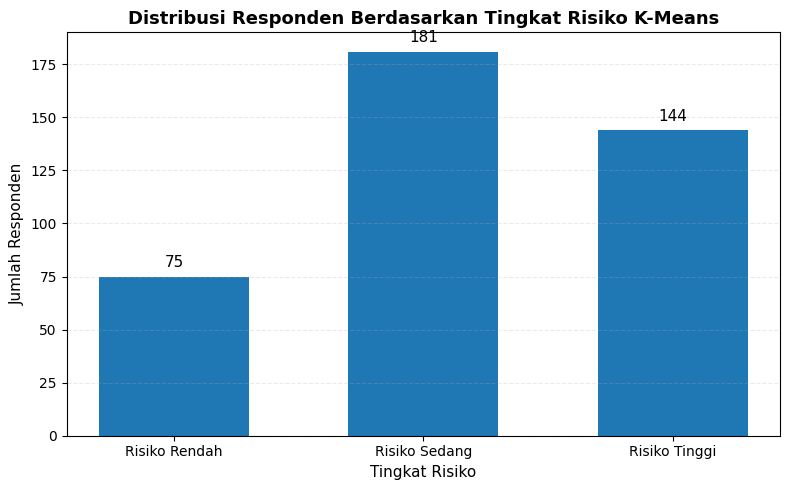

In [92]:
# Urutan tingkat risiko untuk visualisasi
urutan_risiko = [
    "Risiko Rendah",
    "Risiko Sedang",
    "Risiko Tinggi"
]

# Jumlah berdasarkan mapping cluster
cluster_counts_risiko = {
    "Risiko Rendah": (hasil_clustering["Cluster"] == 1).sum(),
    "Risiko Sedang": (hasil_clustering["Cluster"] == 3).sum(),
    "Risiko Tinggi": (hasil_clustering["Cluster"] == 2).sum()
}

values = [
    cluster_counts_risiko[r]
    for r in urutan_risiko
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    urutan_risiko,
    values,
    width=0.6
)

plt.xlabel(
    "Tingkat Risiko",
    fontsize=11
)

plt.ylabel(
    "Jumlah Responden",
    fontsize=11
)

plt.title(
    "Distribusi Responden Berdasarkan Tingkat Risiko K-Means",
    fontsize=13,
    fontweight="bold"
)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 3,
        str(value),
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()
plt.show()

PROFIL CLUSTER K-MEANS

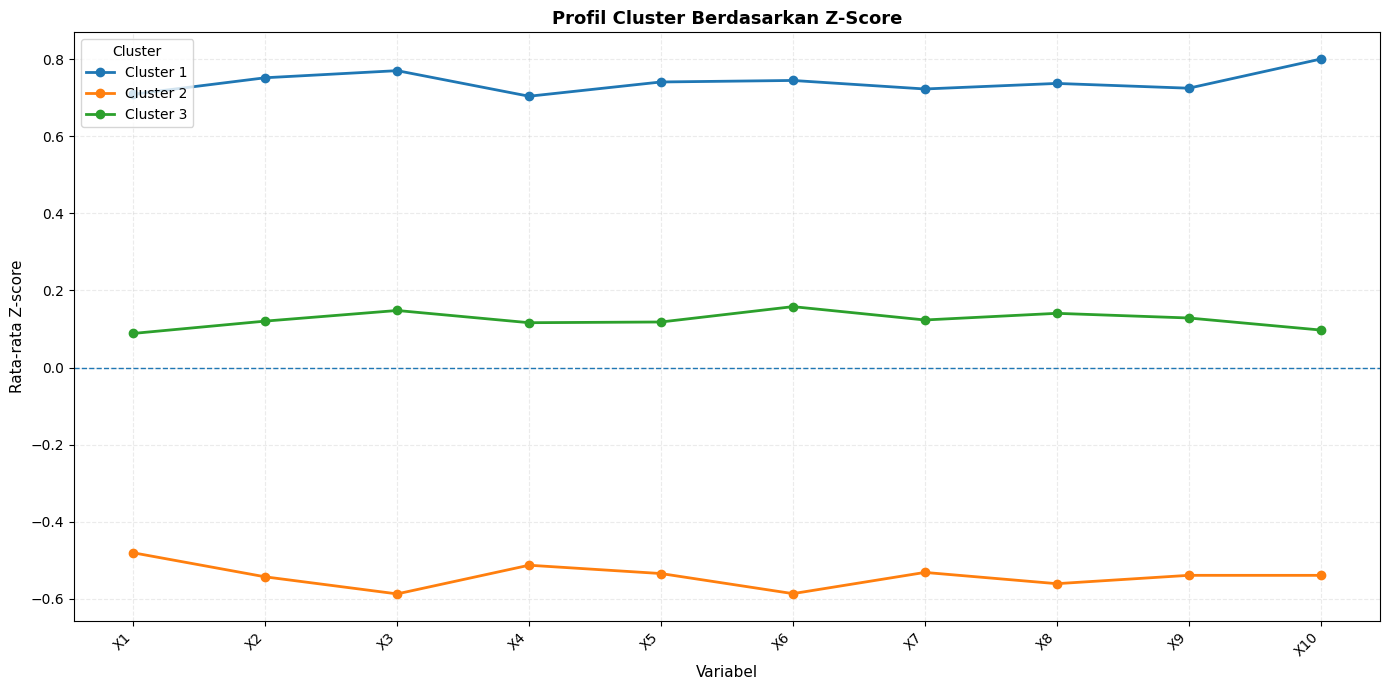

In [93]:
profil_cluster_z = X_z.copy()

profil_cluster_z["Cluster"] = cluster_kmeans

profil_cluster_mean = (
    profil_cluster_z
    .groupby("Cluster")
    .mean()
)

plt.figure(figsize=(14, 7))

for cluster in profil_cluster_mean.index:
    plt.plot(
        profil_cluster_mean.columns,
        profil_cluster_mean.loc[cluster],
        marker="o",
        linewidth=2,
        markersize=6,
        label=f"Cluster {cluster}"
    )

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Variabel",
    fontsize=11
)

plt.ylabel(
    "Rata-rata Z-score",
    fontsize=11
)

plt.title(
    "Profil Cluster Berdasarkan Z-Score",
    fontsize=13,
    fontweight="bold"
)

plt.xticks(
    rotation=45,
    ha="right"
)

# LEGEND DI DALAM GRAFIK, KIRI ATAS
plt.legend(
    title="Cluster",
    loc="upper left",
    frameon=True
)

plt.grid(
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()
plt.show()

HEATMAP PROFIL CLUSTER

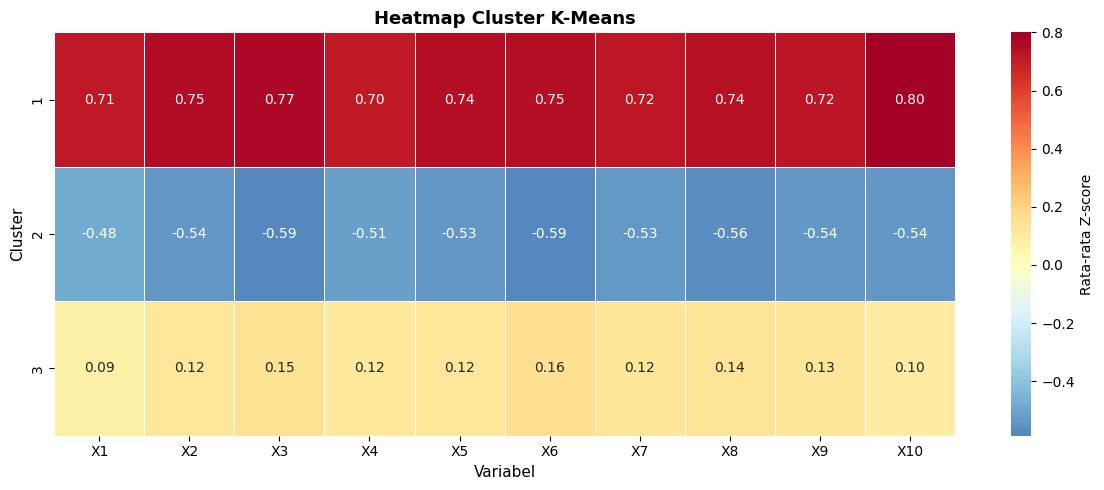

In [94]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    profil_cluster_mean,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={
        "label": "Rata-rata Z-score"
    }
)

plt.xlabel(
    "Variabel",
    fontsize=11
)

plt.ylabel(
    "Cluster",
    fontsize=11
)

plt.title(
    "Heatmap Cluster K-Means",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

VISUALISASI SCATTER PLOT HASIL CLUSTERING K-MEANS

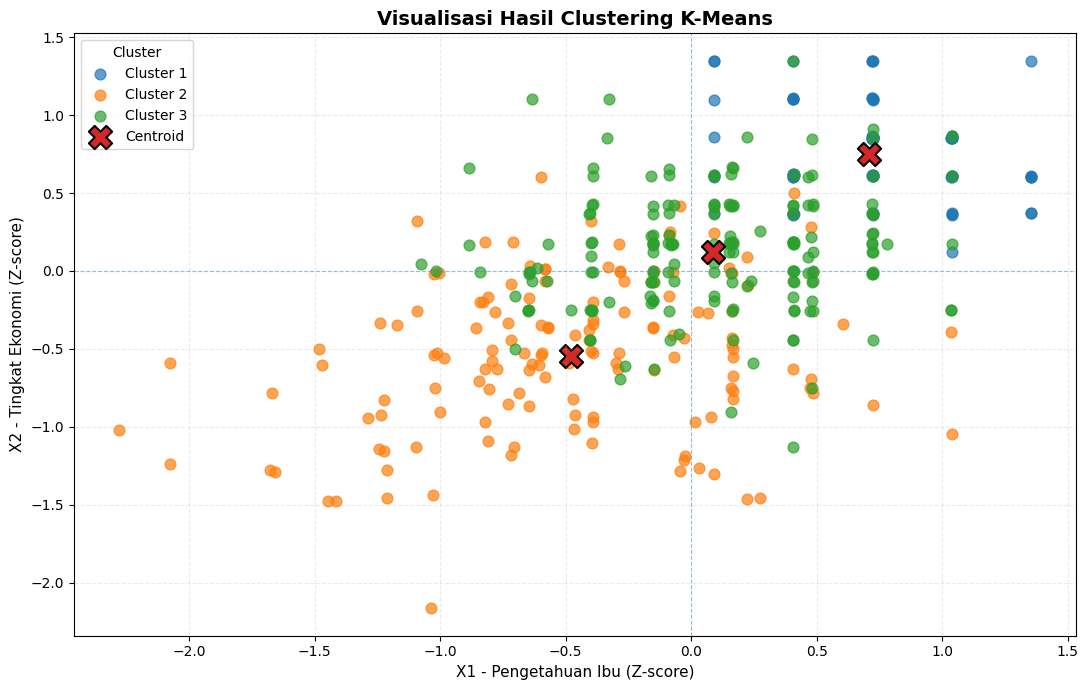

In [95]:
plot_data = X_z.copy()

plot_data["Cluster"] = cluster_kmeans

x_var = "X1"
y_var = "X2"

plt.figure(figsize=(11, 7))

for cluster in sorted(
    plot_data["Cluster"].unique()
):

    data_cluster = plot_data[
        plot_data["Cluster"] == cluster
    ]

    plt.scatter(
        data_cluster[x_var],
        data_cluster[y_var],
        s=60,
        alpha=0.70,
        label=f"Cluster {cluster}"
    )

centroid_x = kmeans.cluster_centers_[
    :,
    X_z.columns.get_loc(x_var)
]

centroid_y = kmeans.cluster_centers_[
    :,
    X_z.columns.get_loc(y_var)
]

plt.scatter(
    centroid_x,
    centroid_y,
    marker="X",
    s=280,
    edgecolor="black",
    linewidth=1.5,
    label="Centroid"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=0.8,
    alpha=0.4
)

plt.axvline(
    x=0,
    linestyle="--",
    linewidth=0.8,
    alpha=0.4
)

plt.xlabel(
    "X1 - Pengetahuan Ibu (Z-score)",
    fontsize=11
)

plt.ylabel(
    "X2 - Tingkat Ekonomi (Z-score)",
    fontsize=11
)

plt.title(
    "Visualisasi Hasil Clustering K-Means",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    title="Cluster",
    frameon=True
)

plt.grid(
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()

plt.show()

Scatter Plot X1 vs X3

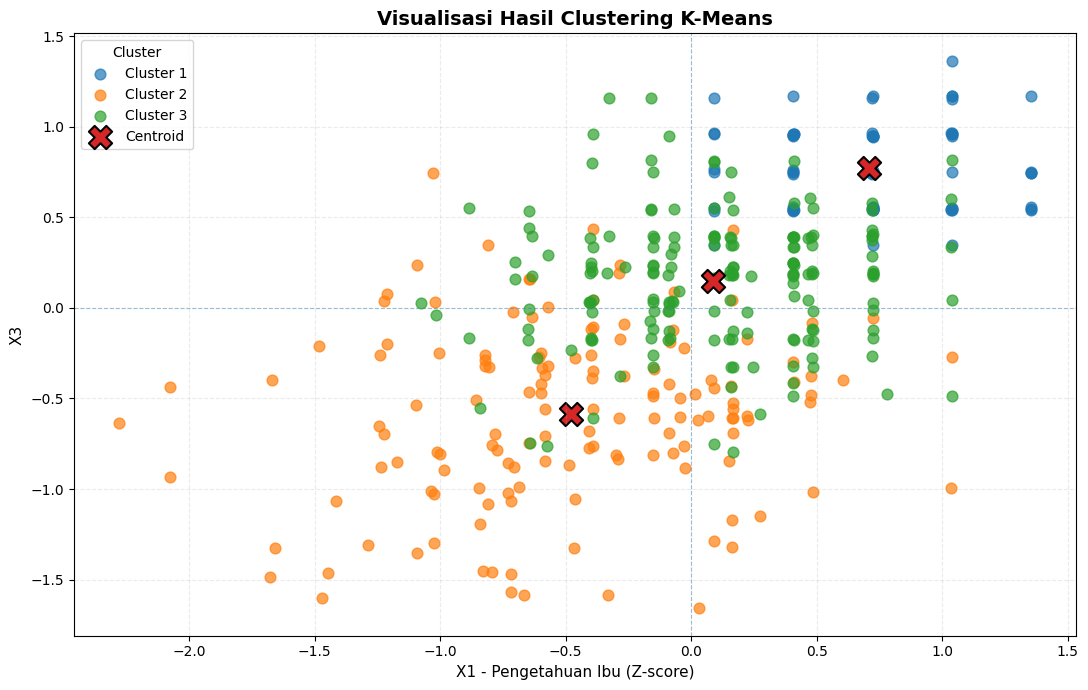

In [96]:
plot_data = X_z.copy()

plot_data["Cluster"] = cluster_kmeans

x_var = "X1"
y_var = "X3"

plt.figure(figsize=(11, 7))

for cluster in sorted(
    plot_data["Cluster"].unique()
):

    data_cluster = plot_data[
        plot_data["Cluster"] == cluster
    ]

    plt.scatter(
        data_cluster[x_var],
        data_cluster[y_var],
        s=60,
        alpha=0.70,
        label=f"Cluster {cluster}"
    )

centroid_x = kmeans.cluster_centers_[
    :,
    X_z.columns.get_loc(x_var)
]

centroid_y = kmeans.cluster_centers_[
    :,
    X_z.columns.get_loc(y_var)
]

plt.scatter(
    centroid_x,
    centroid_y,
    marker="X",
    s=280,
    edgecolor="black",
    linewidth=1.5,
    label="Centroid"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=0.8,
    alpha=0.4
)

plt.axvline(
    x=0,
    linestyle="--",
    linewidth=0.8,
    alpha=0.4
)

plt.xlabel(
    "X1 - Pengetahuan Ibu (Z-score)",
    fontsize=11
)

plt.ylabel(
    "X3",
    fontsize=11
)

plt.title(
    "Visualisasi Hasil Clustering K-Means",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    title="Cluster",
    frameon=True
)

plt.grid(
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()

plt.show()

PROFILING HIERARKIS: VARIABEL → INDIKATOR → ITEM


In [97]:

# ==========================================
# PROFILING HIERARKIS
# ==========================================
# Profiling menggunakan:
# - Z-score item untuk menentukan urutan/karakteristik yang paling menonjol.
# - Rata-rata skor asli skala 1-5 untuk ditampilkan sebagai persentase capaian.
#
# Persentase capaian = rata-rata skor asli / 5 x 100%.
# Persentase ini BUKAN persentase kontribusi risiko.

# Informasi indikator dan item dibaca dari variable_database.json.
FILE_PATH = "/Users/lunaaqillah/Downloads/STUNTRACK_9 (2) 3/backend/data/data_responden.json"

BASE_DIR = os.path.dirname(FILE_PATH)

VARIABLE_DB_PATH = os.path.join(
    BASE_DIR,
    "variable_database.json"
)

with open(VARIABLE_DB_PATH, encoding="utf-8") as f:
    variable_db = json.load(f)

variable_info = {
    v["id_variabel"]: v["keterangan"]
    for v in variable_db["variables"]
    if v["id_variabel"].startswith("X")
}

indicator_info = [
    x for x in variable_db["indicators"]
    if x["id_variabel"].startswith("X")
]

item_info = [
    x for x in variable_db["items"]
    if x["id_variabel"].startswith("X")
]

# Cluster -> risk
cluster_to_risk = {
    int(cluster): (
        "tinggi" if nama_risiko[cluster] == "Risiko Tinggi"
        else "rendah" if nama_risiko[cluster] == "Risiko Rendah"
        else "sedang"
    )
    for cluster in nama_risiko
}

segment_profile = pd.DataFrame({
    "Cluster": cluster_kmeans
})
segment_profile["Segmen"] = segment_profile["Cluster"].map(cluster_to_risk)

# Pecah cluster sedang berdasarkan jarak ke centroid tinggi dan rendah.
cluster_tinggi = [
    c for c, r in cluster_to_risk.items() if r == "tinggi"
][0]
cluster_rendah = [
    c for c, r in cluster_to_risk.items() if r == "rendah"
][0]

idx_sedang = segment_profile.index[
    segment_profile["Segmen"] == "sedang"
]

jarak_ke_tinggi = np.linalg.norm(
    X_z.loc[idx_sedang].values -
    kmeans.cluster_centers_[cluster_tinggi - 1],
    axis=1
)

jarak_ke_rendah = np.linalg.norm(
    X_z.loc[idx_sedang].values -
    kmeans.cluster_centers_[cluster_rendah - 1],
    axis=1
)

segment_profile.loc[idx_sedang, "Segmen"] = np.where(
    jarak_ke_tinggi <= jarak_ke_rendah,
    "sedang_mendekati_tinggi",
    "sedang_mendekati_rendah"
)

SEGMENT_ORDER = [
    "tinggi",
    "sedang_mendekati_tinggi",
    "sedang_mendekati_rendah",
    "rendah"
]

SEGMENT_LABEL = {
    "tinggi": "Risiko Tinggi",
    "sedang_mendekati_tinggi": "Sedang Mendekati Tinggi",
    "sedang_mendekati_rendah": "Sedang Mendekati Rendah",
    "rendah": "Risiko Rendah"
}

def _percentage(raw_mean):
    return round(float(raw_mean) / 5 * 100, 2)

def _cols_for_indicator(var, indicator_id):
    return [
        c for c in variable_groups[var]
        if c.split("_", 1)[1].startswith(indicator_id + ".")
    ]

profil_hierarkis = {}

for seg in SEGMENT_ORDER:
    idx = segment_profile.index[
        segment_profile["Segmen"] == seg
    ]

    variable_rows = []

    for var in [f"X{i}" for i in range(1, 11)]:
        cols = variable_groups[var]

        z_mean = float(df_msi_z.loc[idx, cols].mean().mean())
        raw_mean = float(df.loc[idx, cols].mean().mean())

        variable_rows.append({
            "id": var.lower(),
            "code": var,
            "label": variable_info[var],
            "z_mean": round(z_mean, 6),
            "raw_mean": round(raw_mean, 4),
            "percentage": _percentage(raw_mean)
        })

    variable_rows.sort(
        key=lambda x: x["z_mean"],
        reverse=True
    )

    top_variables = []

    for var_row in variable_rows[:3]:
        var = var_row["code"]
        indicator_rows = []

        for ind in indicator_info:
            if ind["id_variabel"] != var:
                continue

            iid = ind["id_indikator"]
            cols = _cols_for_indicator(var, iid)

            z_mean = float(
                df_msi_z.loc[idx, cols].mean().mean()
            )
            raw_mean = float(
                df.loc[idx, cols].mean().mean()
            )

            indicator_rows.append({
                "id": iid.lower(),
                "code": iid,
                "label": ind["keterangan"],
                "z_mean": round(z_mean, 6),
                "raw_mean": round(raw_mean, 4),
                "percentage": _percentage(raw_mean)
            })

        indicator_rows.sort(
            key=lambda x: x["z_mean"],
            reverse=True
        )

        var_row["top_indicator"] = (
            indicator_rows[0]
            if indicator_rows else None
        )

        if indicator_rows:
            top_ind = indicator_rows[0]
            iid = top_ind["code"]

            candidate_items = []

            for item in item_info:
                if (
                    item["id_variabel"] != var
                    or item["id_indikator"] != iid
                ):
                    continue

                col = f"{var}_{item['id_item']}"

                z_mean = float(df_msi_z.loc[idx, col].mean())
                raw_mean = float(df.loc[idx, col].mean())

                candidate_items.append({
                    "id": item["id_item"].lower(),
                    "code": item["id_item"],
                    "question": item["pertanyaan"],
                    "z_mean": round(z_mean, 6),
                    "raw_mean": round(raw_mean, 4),
                    "percentage": _percentage(raw_mean)
                })

            candidate_items.sort(
                key=lambda x: x["z_mean"],
                reverse=True
            )

            top_ind["top_item"] = (
                candidate_items[0]
                if candidate_items else None
            )

        top_variables.append(var_row)

    profil_hierarkis[seg] = {
        "label": SEGMENT_LABEL[seg],
        "n": int(len(idx)),
        "percentage_of_total": round(
            len(idx) / len(df) * 100,
            2
        ),
        "top_variables": top_variables,
        "all_variables": variable_rows
    }

display(
    pd.DataFrame([
        {
            "Segmen": data["label"],
            "Jumlah Responden": data["n"],
            "Persentase": f'{data["percentage_of_total"]:.2f}%'
        }
        for data in profil_hierarkis.values()
    ])
)


,Segmen,Jumlah Responden,Persentase
0,Risiko Tinggi,75,18.75%
1,Sedang Mendekati Tinggi,123,30.75%
2,Sedang Mendekati Rendah,58,14.50%
3,Risiko Rendah,144,36.00%


EKSPOR HASIL PROFILING UNTUK DASHBOARD


In [98]:
# ==========================================
# EKSPOR JSON UNTUK DASHBOARD ADMIN
# ==========================================

FILE_PATH = "/Users/lunaaqillah/Downloads/STUNTRACK_9 (2) 3/backend/data/clustering_insights.json"

BASE_DIR = os.path.dirname(FILE_PATH)

OUTPUT_PROFILE = os.path.join(
    BASE_DIR,
    "clustering_insights.json"
)

with open(OUTPUT_PROFILE, "w", encoding="utf-8") as f:
    json.dump(
        {
            "method": "K-Means",
            "random_state": RANDOM_STATE,
            "k": K,
            "total_responden": len(df),
            "cluster_to_risk": {
                str(k): nama_risiko[k]
                for k in sorted(nama_risiko)
            },
            "profiles": profil_hierarkis
        },
        f,
        ensure_ascii=False,
        indent=2
    )

print(
    "Profiling hierarkis berhasil diekspor ke:",
    OUTPUT_PROFILE
)

Profiling hierarkis berhasil diekspor ke: /Users/lunaaqillah/Downloads/STUNTRACK_9 (2) 3/backend/data/clustering_insights.json
